# Reparametrizacion parabolica del simbolo

`MLPSymbol` es una MLP con `Tanh` y salida lineal, asi que $a_\theta(\mathbf{k})$ es **acotada**. La
parabolicidad (Def. 2.3) exige $|a_\theta(\mathbf{k})|\ge\langle\mathbf{k}\rangle^m/\kappa\to\infty$, de modo que
solo puede cumplirse dentro de la ventana de entrenamiento.

`ParabolicMLPSymbol` saca la escala de la red:

$$x=\frac{\mathbf{k}}{\langle\mathbf{k}\rangle},\qquad
a_\theta(\mathbf{k})=\langle\mathbf{k}\rangle^m\big(c+(C-c)\,\sigma(g_\theta(x))\big)\quad(\mathbf{k}\neq 0),
\qquad a_\theta(0)=0,$$

con $g_\theta$ una MLP con `Tanh` ($C^\infty$) y $\sigma$ la sigmoide. Para todo $\theta$:
$c\langle\mathbf{k}\rangle^m<a_\theta(\mathbf{k})<C\langle\mathbf{k}\rangle^m$, y la Def. 2.3 vale en todo
$\mathbb{Z}^n$ con

$$M=\max(1,2^{m/2-1}),\qquad \kappa=\max\Big(\frac{\sqrt2\,M}{\min(c,1)},\ M\big(1+\omega^{-m}\big)\Big).$$

Las constantes $0<c<C$ se estiman **solo con los datos de entrenamiento** (`estimation.py`).

Contenido:
1. Verificaciones de la construccion con pesos sin entrenar.
2. Estimacion de $\hat a(\mathbf{k})$ y de $(c, C)$ desde los datos, frente al oraculo.
3. Entrenamiento de `ParabolicMLPSymbol` y de `MLPSymbol` con la misma particion y presupuesto.
4. Comparacion dentro y fuera de la ventana de entrenamiento.
5. Sensibilidad a $\delta$ y a la fuente de $(c, C)$.

Referencia: calor en $\mathbb{T}^2$, $a(\mathbf{k})=|\mathbf{k}|^2$ ($n=2$, $m=2$, $\rho=n+1=3$), con los mismos
datos y la misma particion por $\mathbf{k}$ que `mlp_symbol_training.ipynb`.

In [1]:
import sys
sys.path.insert(0, "../src")  # ruta para las clases

import time
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.ParabolicityVerifier import ParabolicityVerifier
from parabolic_symbol.SymbolClassVerifier import SymbolClassVerifier
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.mlp_symbol import MLPSymbol, default_device
from parabolic_symbol.symbols.parabolic_mlp_symbol import ParabolicMLPSymbol
from parabolic_symbol.data import (
    k_grid,
    make_trajectory_data,
    phase_grid,
    sample_phase_points,
    split_trajectory_data,
)
from parabolic_symbol.estimation import (
    estimate_bounds,
    estimate_class_constants,
    estimate_symbol,
    oracle_bounds,
    oracle_class_constants,
    symbol_values,
)
from parabolic_symbol.evaluation import symbol_report, trajectory_report
from parabolic_symbol.losses import parabolicity_loss, parabolicity_terms
from parabolic_symbol.sweep import max_ratio_on
from parabolic_symbol.training import TrainingConfig, train

np.set_printoptions(precision=4, suppress=True)

device = default_device()
# Doble precision siempre: las verificaciones llegan a <k>^m ~ 10^6 y comparan
# contra cotas con igualdad en el limite.
dtype = torch.float64
print(f"device = {device}  |  dtype = {dtype}")

device = cpu  |  dtype = torch.float64


## 0. Datos

Los mismos del notebook original: $10^5$ muestras, $|k_i|\le 12$, $t$ log-uniforme en $[10^{-3},1]$ y
particion **por $\mathbf{k}$** 80/20. No se modifica la generacion.

In [2]:
n = 2
m = 2.0
k_max = 12
omega = 1.0
reference = HeatSymbol(n=n)

data = make_trajectory_data(
    reference, k_max=k_max, n_samples=100000, t_min=1e-3, t_max=1.0, seed=0
)
train_data, val_data = split_trajectory_data(data, val_fraction=0.2, seed=0)

k_train_values = np.unique(train_data["k"].numpy(), axis=0)
k_val_values = np.unique(val_data["k"].numpy(), axis=0)
print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras / {len(k_train_values)} k unicos")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras / {len(k_val_values)} k unicos")

entrenamiento: 79,836 muestras / 500 k unicos
validacion:    20,164 muestras / 125 k unicos


## 1. Verificaciones de la construccion (pesos sin entrenar)

Todo lo de esta seccion debe valer **para cualquier $\theta$**, asi que se prueba con redes recien
inicializadas y varios seeds. Se usa una banda ilustrativa $(c, C)=(0.45, 1.1)$ (la que saldra de
los datos en la seccion 2 es casi esa) y, ademas de $m=2$, ordenes fraccionarios
$m\in\{0.5, 1, 1.5\}$, que son el caso de interes del trabajo.

In [3]:
c_demo, C_demo = 0.45, 1.1
seeds = (0, 1, 2)
orders = (0.5, 1.0, 1.5, 2.0)
hidden = (64, 64, 64)


def untrained(m_, seed, c_=c_demo, C_=C_demo):
    return ParabolicMLPSymbol(n=n, m=m_, c=c_, C=C_, hidden=hidden, seed=seed,
                              device=device, dtype=dtype)


def band_extremes(symbol, K, chunk=250_000):
    # min y max de a_theta(k)/<k>^m sobre k != 0 en |k_i| <= K (por trozos), y a_theta(0).
    ks = np.arange(-K, K + 1, dtype=float)
    k1, k2 = np.meshgrid(ks, ks, indexing="ij")
    k_all = torch.tensor(np.stack([k1.ravel(), k2.ravel()], axis=1), dtype=dtype)
    lo, hi = np.inf, -np.inf
    with torch.no_grad():
        symbol.net.eval()
        for i in range(0, len(k_all), chunk):
            kk = k_all[i : i + chunk]
            nz = torch.sum(kk**2, dim=1) > 0
            h = symbol.forward(kk)[nz] / (1.0 + torch.sum(kk[nz] ** 2, dim=1)) ** (symbol.m / 2)
            lo, hi = min(lo, float(h.min())), max(hi, float(h.max()))
        a0 = float(symbol.forward(torch.zeros(1, n, dtype=dtype))[0])
    return lo, hi, a0

### 1.1 Banda: $c\langle\mathbf{k}\rangle^m < a_\theta(\mathbf{k}) < C\langle\mathbf{k}\rangle^m$ y $a_\theta(0)=0$

Sobre **toda** la rejilla $|k|_\infty\le 10^3$ ($\approx 4\cdot 10^6$ puntos), muy lejos de la ventana de
entrenamiento $|k_i|\le 12$.

In [4]:
K_band = 1000
filas = []
t0 = time.perf_counter()
for m_ in orders:
    for seed in seeds:
        lo, hi, a0 = band_extremes(untrained(m_, seed), K_band)
        filas.append({"m": m_, "seed": seed, "c": c_demo, "min a/<k>^m": lo,
                      "max a/<k>^m": hi, "C": C_demo, "a(0)": a0,
                      "cumple": (c_demo < lo) and (hi < C_demo) and a0 == 0.0})
banda = pd.DataFrame(filas)
display(banda)
print(f"|k|_inf <= {K_band}: {(2 * K_band + 1) ** n:,} k por red, {time.perf_counter() - t0:.1f}s")
assert banda["cumple"].all()

,m,seed,c,min a/<k>^m,max a/<k>^m,C,a(0),cumple
0,0.5,0,0.45,0.764551,0.781404,1.1,0.0,True
1,0.5,1,0.45,0.743350,0.762893,1.1,0.0,True
2,0.5,2,0.45,0.761697,0.764245,1.1,0.0,True
3,1.0,0,0.45,0.764551,0.781404,1.1,0.0,True
4,1.0,1,0.45,0.743350,0.762893,1.1,0.0,True
5,1.0,2,0.45,0.761697,0.764245,1.1,0.0,True
6,1.5,0,0.45,0.764551,0.781404,1.1,0.0,True
7,1.5,1,0.45,0.743350,0.762893,1.1,0.0,True
8,1.5,2,0.45,0.761697,0.764245,1.1,0.0,True
9,2.0,0,0.45,0.764551,0.781404,1.1,0.0,True


|k|_inf <= 1000: 4,004,001 k por red, 57.5s


### 1.2 $\kappa$ teorico

Comprobacion pedida: $m=2$, $c=1/2$ da $\kappa=2\sqrt2$. La tabla muestra tambien que termino domina
($\kappa_1$, todo $\mathbf{k}\neq0$; o $\kappa_0$, el modo cero) para varios $(m, c)$, con $\omega=1$.

In [5]:
kappa_check = untrained(2.0, 0, c_=0.5, C_=1.2).theoretical_kappa(omega=1.0)
print(f"m = 2, c = 1/2: kappa = {kappa_check:.12f}   2*sqrt(2) = {2 * np.sqrt(2):.12f}")
assert np.isclose(kappa_check, 2 * np.sqrt(2), rtol=0, atol=1e-14)

filas = []
for m_ in orders:
    for c_ in (0.25, 0.45, 0.5, 0.9, 1.5):
        M = max(1.0, 2 ** (m_ / 2 - 1))
        filas.append({"m": m_, "c": c_, "M": M,
                      "kappa_1": np.sqrt(2) * M / min(c_, 1.0), "kappa_0": M * (1 + 1 / omega**m_),
                      "kappa": untrained(m_, 0, c_=c_, C_=2 * c_).theoretical_kappa(omega)})
display(pd.DataFrame(filas).pivot(index="c", columns="m", values="kappa"))

m = 2, c = 1/2: kappa = 2.828427124746   2*sqrt(2) = 2.828427124746


m,0.5,1.0,1.5,2.0
c,,,,
0.25,5.656854,5.656854,5.656854,5.656854
0.45,3.142697,3.142697,3.142697,3.142697
0.50,2.828427,2.828427,2.828427,2.828427
0.90,2.000000,2.000000,2.000000,2.000000
1.50,2.000000,2.000000,2.000000,2.000000


### 1.3 `ParabolicityVerifier` con $\kappa$ teorico

Rejilla $(\mathbf{k},\lambda)$ con $\mathrm{Re}\,\lambda\ge0$ (incluida la frontera $\mathrm{Re}\,\lambda=0$),
$|\lambda|\in[10^{-2},10^3]$ y $|(\mathbf{k},\lambda)|\ge\omega=1$ (el verificador descarta el resto).
Los $\mathbf{k}$: toda la rejilla $|k_i|\le 8$ (incluido $\mathbf{k}=0$) mas $\mathbf{k}$ lejanos hasta
$|k|_\infty=10^3$.

In [6]:
lam_radii = np.logspace(-2, 3, 13)
lam_angles = np.linspace(-np.pi / 2, np.pi / 2, 9)          # extremos: Re(lambda) = 0
lam_verif = list((lam_radii[:, None] * np.exp(1j * lam_angles)).ravel())
far = [(K, 0) for K in (20, 50, 100, 300, 1000)] + [(K, K) for K in (20, 100, 1000)] \
    + [(-1000, 357), (0, -1000)]
k_verif = [np.array(k, dtype=float) for k in k_grid(n, 8)] + [np.array(k, dtype=float) for k in far]

filas = []
t0 = time.perf_counter()
for m_ in orders:
    for seed in seeds:
        symbol_ = untrained(m_, seed)
        kappa_ = symbol_.theoretical_kappa(omega)
        res = ParabolicityVerifier(symbol_).check_region(k_verif, lam_verif, omega, kappa_)
        cero = [r.ratio for r in res if not np.any(r.k)]
        filas.append({"m": m_, "seed": seed, "kappa teorico": kappa_, "puntos": len(res),
                      "max ratio": max(r.ratio for r in res), "max ratio en k=0": max(cero),
                      "puntos en k=0": len(cero), "cumple": all(r.holds for r in res)})
verif = pd.DataFrame(filas)
display(verif)
print(f"{len(k_verif)} k x {len(lam_verif)} lambda por red, {time.perf_counter() - t0:.1f}s")
assert verif["cumple"].all()

,m,seed,kappa teorico,puntos,max ratio,max ratio en k=0,puntos en k=0,cumple
0,0.5,0,3.142697,34938,0.416162,0.350021,72,True
1,0.5,1,3.142697,34938,0.428019,0.350021,72,True
2,0.5,2,3.142697,34938,0.417735,0.350021,72,True
3,1.0,0,3.142697,34938,0.416166,0.412590,72,True
4,1.0,1,3.142697,34938,0.428023,0.412590,72,True
5,1.0,2,3.142697,34938,0.417739,0.412590,72,True
6,1.5,0,3.142697,34938,0.489171,0.489171,72,True
7,1.5,1,3.142697,34938,0.489171,0.489171,72,True
8,1.5,2,3.142697,34938,0.489171,0.489171,72,True
9,2.0,0,3.142697,34938,0.580840,0.580840,72,True


299 k x 117 lambda por red, 98.9s


### 1.4 $\mathcal{L}_{\text{par}}=0$ con $\kappa$ teorico

La misma perdida de entrenamiento (`parabolicity_loss`), sobre $2\cdot10^5$ puntos aleatorios con
$|k_i|\le 10^3$ y $|\lambda|\in[10^{-3},10^3]$, mas $2\cdot10^3$ puntos forzados en $\mathbf{k}=0$.

In [7]:
k_p, lam_p = sample_phase_points(n, 1000, 200_000, 1e-3, 1e3,
                                 torch.Generator().manual_seed(0), device, dtype)
k_p[:2000] = 0.0
filas = []
for m_ in orders:
    for seed in seeds:
        symbol_ = untrained(m_, seed)
        kappa_ = symbol_.theoretical_kappa(omega)
        with torch.no_grad():
            l_par = parabolicity_loss(symbol_, k_p, lam_p, omega, kappa_)
            _, ratio = parabolicity_terms(symbol_, k_p, lam_p, omega, kappa_)
        filas.append({"m": m_, "seed": seed, "kappa": kappa_, "L_par": float(l_par),
                      "max ratio": float(ratio.max()), "puntos": ratio.numel()})
lpar = pd.DataFrame(filas)
display(lpar)
assert (lpar["L_par"] == 0.0).all()

,m,seed,kappa,L_par,max ratio,puntos
0,0.5,0,3.142697,0.0,0.416189,199018
1,0.5,1,3.142697,0.0,0.428060,199018
2,0.5,2,3.142697,0.0,0.417749,199018
3,1.0,0,3.142697,0.0,0.449314,199018
4,1.0,1,3.142697,0.0,0.449314,199018
5,1.0,2,3.142697,0.0,0.449314,199018
6,1.5,0,3.142697,0.0,0.534327,199018
7,1.5,1,3.142697,0.0,0.534327,199018
8,1.5,2,3.142697,0.0,0.534327,199018
9,2.0,0,3.142697,0.0,0.635426,199018


### 1.5 Clase $S^{m,\rho}$: `SymbolClassVerifier` sobre ventanas crecientes

La pertenencia es cualitativa (producto de $\langle\mathbf{k}\rangle^m\in S^m$ por una funcion suave y
acotada de $x=\mathbf{k}/\langle\mathbf{k}\rangle$, que es de orden 0), pero las $C_\alpha$ dependen de
$\theta$. Se espera que $\hat C_\alpha(K)$ se estabilice al crecer $K$ para todo $|\alpha|\le\rho$.

In [8]:
class_windows = (8, 16, 32, 64)
for seed in seeds:
    resultados = SymbolClassVerifier(untrained(2.0, seed)).check(k_maxs=class_windows)
    tabla = pd.DataFrame([
        {"alpha": str(r.alpha), "|alpha|": r.order,
         **{f"C_hat({K})": r.c_hat[K] for K in class_windows},
         f"crecim.({class_windows[-2]}->{class_windows[-1]})": r.growth,
         "pendiente": r.slope, "m-|alpha|": r.slope_theoretical,
         "estable": r.stable, "consistente": r.consistent}
        for r in resultados
    ])
    print(f"seed = {seed}: consistentes {int(tabla['consistente'].sum())} de {len(tabla)}")
    if seed == seeds[0]:
        display(tabla)

seed = 0: consistentes 10 de 10


,alpha,|alpha|,C_hat(8),C_hat(16),C_hat(32),C_hat(64),crecim.(32->64),pendiente,m-|alpha|,estable,consistente
0,"(0, 0)",0,0.781372,0.781397,0.781402,0.781404,1.000002,2.000002,2.0,True,True
1,"(0, 1)",1,1.742259,1.742259,1.742259,1.742259,1.000000,0.989357,1.0,True,True
2,"(1, 0)",1,1.713436,1.713436,1.713436,1.713436,1.000000,0.894235,1.0,True,True
3,"(0, 2)",2,3.090421,3.090421,3.090421,3.090421,1.000000,0.000002,0.0,True,True
4,"(1, 1)",2,0.775133,0.775133,0.775133,0.775133,1.000000,0.001318,0.0,True,True
5,"(2, 0)",2,3.090344,3.090344,3.090344,3.090344,1.000000,0.000001,0.0,True,True
6,"(0, 3)",3,5.210058,5.210058,5.210058,5.210058,1.000000,-0.998388,-1.0,True,True
7,"(1, 2)",3,2.673701,2.673701,2.673701,2.673701,1.000000,-0.999073,-1.0,True,True
8,"(2, 1)",3,2.682837,2.682837,2.682837,2.682837,1.000000,-1.018875,-1.0,True,True
9,"(3, 0)",3,5.163620,5.163620,5.163620,5.163620,1.000000,-1.006410,-1.0,True,True


seed = 1: consistentes 10 de 10
seed = 2: consistentes 10 de 10


## 2. Estimacion desde los datos de entrenamiento

Para cada $\mathbf{k}$ de entrenamiento se ajusta por minimos cuadrados ponderados (pesos $|\hat u_0|^2$)
la recta $\log|\hat u(t,\mathbf{k})/\hat u_0(\mathbf{k})|=-t\,a(\mathbf{k})$, descartando los pares con
$|\hat u|\le 10^{-10}|\hat u_0|$. Luego $\hat h(\mathbf{k})=\hat a(\mathbf{k})/\langle\mathbf{k}\rangle^m$ y
$c=(1-\delta)\min\hat h$, $C=(1+\delta)\max\hat h$.

**Nota:** los datos del repo no tienen ruido, $\hat u=e^{-ta}\hat u_0$ exacto, asi que el ajuste
recupera $a(\mathbf{k})$ hasta redondeo y las cotas de los datos coinciden con las del oraculo en la
misma ventana.

In [9]:
k_est, a_hat = estimate_symbol(train_data, tol=1e-10)
a_exact = symbol_values(reference, k_est)
print(f"max |a_hat - a| = {np.abs(a_hat - a_exact).max():.3e}   "
      f"(max relativo {np.max(np.abs(a_hat - a_exact) / np.maximum(a_exact, 1)):.3e})")

delta = 0.1
bounds_data = estimate_bounds(k_est, a_hat, m, delta=delta)
bounds_oracle = oracle_bounds(reference, k_est, m, delta=delta)        # mismos k de entrenamiento
bounds_oracle_wide = oracle_bounds(reference, 200, m, delta=delta)     # ventana amplia |k_i| <= 200

display(pd.DataFrame([
    {"fuente": "datos (k de entrenamiento)", "c": bounds_data.c, "C": bounds_data.C,
     "ventana": str(bounds_data.window)},
    {"fuente": "oraculo (k de entrenamiento)", "c": bounds_oracle.c, "C": bounds_oracle.C,
     "ventana": str(bounds_oracle.window)},
    {"fuente": "oraculo (|k_i| <= 200)", "c": bounds_oracle_wide.c, "C": bounds_oracle_wide.C,
     "ventana": str(bounds_oracle_wide.window)},
]))
print(f"cotas globales exactas de h = |k|^2/<k>^2 sobre Z^2 \\ 0: inf = 2^(-m/2) = {2 ** (-m / 2):.4f}, sup = 1")

estimate_symbol: 64,910 de 79,836 pares (k, t) recuperables (tol=1e-10); 500 de 500 k de entrenamiento
  ventana usada: 500 k, |k|_inf <= 12, |k| in [1, 17]
max |a_hat - a| = 2.274e-13   (max relativo 1.463e-15)


,fuente,c,C,ventana
0,datos (k de entrenamiento),0.45,1.096194,"500 k, |k|_inf <= 12, |k| in [1, 17]"
1,oraculo (k de entrenamiento),0.45,1.096194,"500 k, |k|_inf <= 12, |k| in [1, 17]"
2,oraculo (|k_i| <= 200),0.45,1.099986,"160800 k, |k|_inf <= 200, |k| in [1, 283]"


cotas globales exactas de h = |k|^2/<k>^2 sobre Z^2 \ 0: inf = 2^(-m/2) = 0.5000, sup = 1


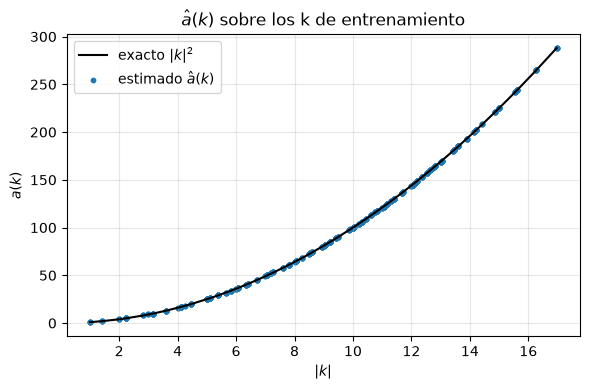

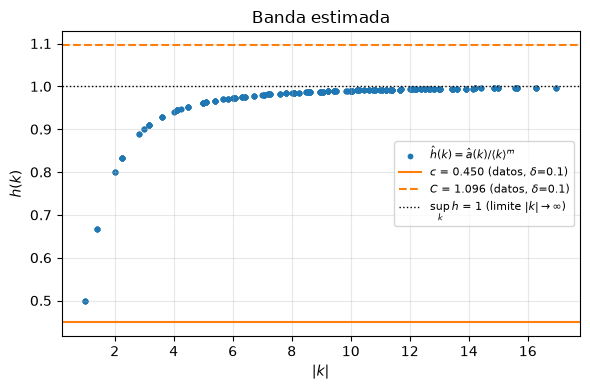

In [10]:
norm_est = np.linalg.norm(k_est, axis=1)
bracket_est = np.sqrt(1 + norm_est**2)
order = np.argsort(norm_est)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(norm_est[order], a_exact[order], "k-", lw=1.5, label=r"exacto $|k|^2$")
ax.scatter(norm_est, a_hat, s=10, color="C0", label=r"estimado $\hat a(k)$")
ax.set_xlabel(r"$|k|$")
ax.set_ylabel(r"$a(k)$")
ax.set_title(r"$\hat a(k)$ sobre los k de entrenamiento")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

nz = norm_est > 0
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(norm_est[nz], a_hat[nz] / bracket_est[nz] ** m, s=10, color="C0",
           label=r"$\hat h(k)=\hat a(k)/\langle k\rangle^m$")
ax.axhline(bounds_data.c, color="C1", lw=1.5, label=rf"$c$ = {bounds_data.c:.3f} (datos, $\delta$={delta})")
ax.axhline(bounds_data.C, color="C1", lw=1.5, ls="--", label=rf"$C$ = {bounds_data.C:.3f} (datos, $\delta$={delta})")
ax.axhline(1.0, color="k", lw=1, ls=":", label=r"$\sup_k h$ = 1 (limite $|k|\to\infty$)")
ax.set_xlabel(r"$|k|$")
ax.set_ylabel(r"$h(k)$")
ax.set_title("Banda estimada")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.1 Constantes $C_\alpha$ de $\mathcal{L}_{\text{class}}$: datos frente a oraculo

`estimate_class_constants` usa diferencias finitas de $\hat a$ sobre los $\mathbf{k}$ de entrenamiento
cuyo estencil completo esta en el conjunto; `oracle_class_constants` es la receta del notebook
original (simbolo exacto en $|k_i|\le k_{\max}$). Ambas con margen $1.5$ y el mismo piso para los
$C_\alpha$ nulos. En la configuracion de entrenamiento se elige con `class_C_source="data"` u
`"oracle"`.

In [11]:
C_data = estimate_class_constants(k_est, a_hat, m, rho=n + 1, margin=1.5)
C_oracle = oracle_class_constants(reference, k_max, margin=1.5, rho=n + 1)
display(pd.DataFrame({"datos": {str(a): v for a, v in C_data.items()},
                      "oraculo": {str(a): v for a, v in C_oracle.items()}}))

,datos,oraculo
"(0, 0)",1.494810,1.494810
"(0, 1)",3.354102,3.354102
"(1, 0)",3.354102,3.354102
"(0, 2)",3.000000,3.000000
"(1, 1)",1.494810,1.494810
"(2, 0)",3.000000,3.000000
"(0, 3)",1.494810,1.494810
"(1, 2)",1.494810,1.494810
"(2, 1)",1.494810,1.494810
"(3, 0)",1.494810,1.494810


## 3. Entrenamiento: `ParabolicMLPSymbol` frente a `MLPSymbol`

Misma particion, misma arquitectura ($3\times64$, `Tanh`), mismo optimizador y mismo presupuesto de
epocas. Decisiones:

- **$\kappa$:** ambos modelos usan el $\kappa$ teorico de `ParabolicMLPSymbol` con la banda de los
  datos, asi $\mathcal{L}_{\text{par}}$ y el ratio de parabolicidad son comparables.
- **$\mathcal{L}_{\text{class}}$:** ambos con $C_\alpha$ de los datos (`class_C_source="data"`).
- **Early stopping:** criterio por defecto (sin $\mathcal{L}_{\text{class}}$).
- `MLPSymbol` conserva sus escalas del notebook original (`input_scale=k_max`,
  `output_scale=k_max**2`); `ParabolicMLPSymbol` no las tiene.

In [12]:
c_data, C_data_band = bounds_data.c, bounds_data.C
hidden = (64, 64, 64)

parabolic = ParabolicMLPSymbol(n=n, m=m, c=c_data, C=C_data_band, hidden=hidden,
                               seed=0, device=device, dtype=dtype)
kappa_theo = parabolic.theoretical_kappa(omega)
print(f"(c, C) de los datos = ({c_data:.4f}, {C_data_band:.4f})  ->  kappa teorico = {kappa_theo:.4f}")

base_config = TrainingConfig(
    epochs=150,
    batch_size=1024,
    lr=1e-3,
    lr_final=1e-5,
    omega=omega,
    kappa=kappa_theo,
    lambda_trajectory=1.0,
    lambda_parabolicity=1.0,
    lambda_class=1.0,
    class_C_source="data",   # C_alpha por diferencias finitas de a_hat (Parte 1.4)
    k_max=k_max,
    lam_min=1e-2,
    lam_max=1e2,
    grad_clip=1.0,
    patience=30,
    n_phase_eval=8192,
    log_every=25,
    seed=0,
)

t0 = time.perf_counter()
result_parabolic = train(parabolic, train_data, val_data, base_config)
time_parabolic = time.perf_counter() - t0
print(f"ParabolicMLPSymbol: {time_parabolic:.0f}s\n")

mlp = MLPSymbol(n=n, m=m, hidden=hidden, input_scale=k_max, output_scale=k_max**2,
                seed=0, device=device, dtype=dtype)
t0 = time.perf_counter()
result_mlp = train(mlp, train_data, val_data, base_config)
time_mlp = time.perf_counter() - t0
print(f"MLPSymbol: {time_mlp:.0f}s")

(c, C) de los datos = (0.4500, 1.0962)  ->  kappa teorico = 3.1427
hidden=(64, 64, 64) | dropout OFF | weight_decay=0 en 2 Linear interiores
epoca   25 | val: total=2.453e-06 traj=2.453e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0034 max_ratio=0.709 viol= 0.00%
epoca   50 | val: total=1.489e-06 traj=1.489e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0027 max_ratio=0.710 viol= 0.00%
epoca   75 | val: total=1.944e-06 traj=1.944e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0031 max_ratio=0.709 viol= 0.00%
epoca  100 | val: total=1.461e-06 traj=1.461e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0026 max_ratio=0.710 viol= 0.00%
early stopping en la epoca 113 (mejor: 83)
ParabolicMLPSymbol: 232s

hidden=(64, 64, 64) | dropout OFF | weight_decay=0 en 2 Linear interiores
epoca   25 | val: total=2.382e+02 traj=2.382e+02 par=8.280e-02 class=8.816e-03 rel_l2=33.8029 max_ratio=31.817 viol= 2.08%
epoca   50 | val: total=2.171e-03 traj=2.171e-03 par=0.000e+00 class=3.293e-04 rel_l2=0.1021 max_ratio=0.709 

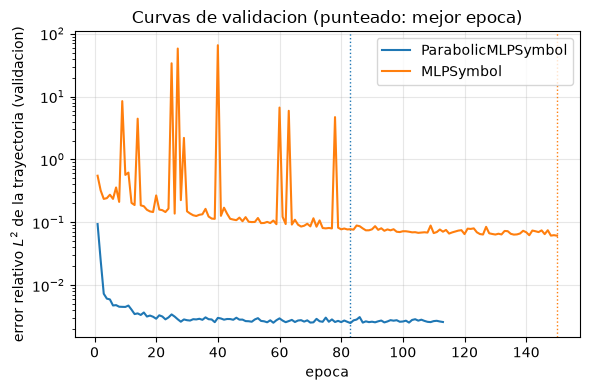

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
for nombre, res, color in (("ParabolicMLPSymbol", result_parabolic, "C0"), ("MLPSymbol", result_mlp, "C1")):
    h = res.history["val"]["rel_l2"]
    ax.semilogy(np.arange(1, len(h) + 1), h, color=color, label=nombre)
    ax.axvline(res.best_epoch, color=color, ls=":", lw=1)
ax.set_xlabel("epoca")
ax.set_ylabel(r"error relativo $L^2$ de la trayectoria (validacion)")
ax.set_title("Curvas de validacion (punteado: mejor epoca)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Comparacion

### 4.1 Trayectoria y simbolo en los $\mathbf{k}$ de validacion, y $\mathcal{L}_{\text{par}}$

In [14]:
models = {"ParabolicMLPSymbol": (parabolic, result_parabolic),
          "MLPSymbol": (mlp, result_mlp)}

filas = {}
for nombre, (sym, res) in models.items():
    traj_val = trajectory_report(sym, val_data)
    sym_val = symbol_report(sym, reference, k_val_values)
    e = res.best_epoch - 1
    filas[nombre] = {
        "traj val rel_l2": traj_val["rel_l2"],
        "traj val rmse": traj_val["rmse"],
        "traj val r2": traj_val["r2"],
        "simbolo val rel_l2": sym_val["rel_l2"],
        "simbolo val max_error": sym_val["max_error"],
        "L_par val (mejor epoca)": res.history["val"]["parabolicity"][e],
        "L_class val (mejor epoca)": res.history["val"]["class"][e],
        "mejor epoca": res.best_epoch,
        "epocas": len(res.history["val"]["total"]),
    }
display(pd.DataFrame(filas))

,ParabolicMLPSymbol,MLPSymbol
traj val rel_l2,0.002501,0.061301
traj val rmse,0.001142,0.027986
traj val r2,0.999994,0.996242
simbolo val rel_l2,0.004391,0.193472
simbolo val max_error,1.612112,90.165270
L_par val (mejor epoca),0.000000,0.000000
L_class val (mejor epoca),0.000000,0.000054
mejor epoca,83.000000,150.000000
epocas,113.000000,150.000000


### 4.2 Parabolicidad en la rejilla de certificacion

La rejilla de certificacion del notebook original: $|\lambda|$ log-espaciado en $[10^{-2},10^3]$ con
$25$ angulos en $[-\pi/2,\pi/2]$, y $\mathbf{k}$ en ventanas $|k_i|\le K$ hasta $3k_{\max}=36$.
Ambos modelos con el mismo $\kappa$ (el teorico). Se reporta tambien $\mathcal{L}_{\text{par}}$
(hinge$^2$ medio) sobre la rejilla y el $\hat\kappa$ minimo que la certificaria.

In [15]:
cert_radii = np.logspace(-2, 3, 25)
cert_angles = np.linspace(-np.pi / 2, np.pi / 2, 25)
cert_lam = (cert_radii[:, None] * np.exp(1j * cert_angles)).ravel()
cert_k_max = 3 * k_max


def cert_metrics(sym, k_window, kappa, chunk=200_000):
    # Peor ratio y L_par sobre (|k_i| <= k_window) x cert_lam, por trozos.
    kk, ll = phase_grid(n, k_window, cert_lam, device=device, dtype=dtype)
    worst, sq_sum, count = 0.0, 0.0, 0
    with torch.no_grad():
        for i in range(0, kk.shape[0], chunk):
            violation, ratio = parabolicity_terms(sym, kk[i : i + chunk], ll[i : i + chunk], omega, kappa)
            worst = max(worst, float(ratio.max()))
            sq_sum += float(torch.sum(violation**2))
            count += violation.numel()
    return worst, sq_sum / count


filas = []
for nombre, (sym, _) in models.items():
    for window in (k_max, 2 * k_max, cert_k_max):
        worst, l_par = cert_metrics(sym, window, kappa_theo)
        filas.append({"modelo": nombre, "|k_i| <=": window,
                      "ventana": "dentro" if window <= k_max else "fuera",
                      "max ratio": worst, "L_par": l_par,
                      "kappa_hat minimo": kappa_theo * worst, "cumple": worst <= 1.0})
display(pd.DataFrame(filas))

,modelo,|k_i| <=,ventana,max ratio,L_par,kappa_hat minimo,cumple
0,ParabolicMLPSymbol,12,dentro,0.720867,0.000000e+00,2.265467,True
1,ParabolicMLPSymbol,24,fuera,0.720867,0.000000e+00,2.265467,True
2,ParabolicMLPSymbol,36,fuera,0.720867,0.000000e+00,2.265467,True
3,MLPSymbol,12,dentro,0.708209,0.000000e+00,2.225685,True
4,MLPSymbol,24,fuera,1.329444,2.062594e-09,4.178040,False
5,MLPSymbol,36,fuera,2.834316,2.135829e-07,8.907396,False


### 4.3 Lejos de la ventana: $|\mathbf{k}|$ hasta $10^3$

Perfiles a lo largo del eje $\mathbf{k}=(K,0)$ y de la diagonal $\mathbf{k}=(K,K)$, con $K$ hasta $10^3$:
el simbolo aprendido frente a $|\mathbf{k}|^2$, y el peor ratio de parabolicidad sobre `cert_lam`
(incluido $|\lambda|=10^3$) en cada $\mathbf{k}$.

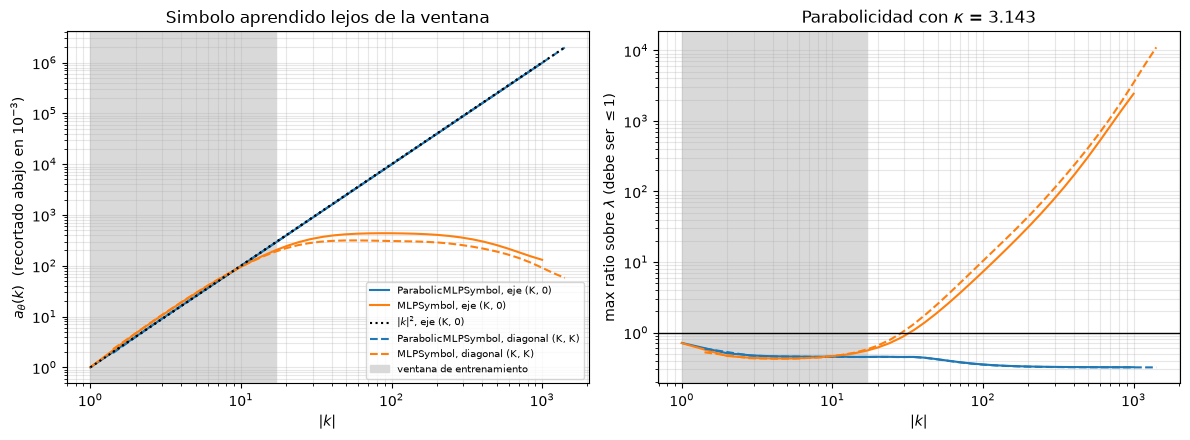

,modelo,perfil,max ratio (|k| <= 17),"max ratio (todo, |k|_inf <= 1000)",a_theta(1000 en el perfil),exacto
0,ParabolicMLPSymbol,"eje (K, 0)",0.712918,0.712918,9.865931e+05,1000000.0
1,ParabolicMLPSymbol,"diagonal (K, K)",0.592615,0.592615,1.983487e+06,2000000.0
2,MLPSymbol,"eje (K, 0)",0.708209,2427.941322,1.310569e+02,1000000.0
3,MLPSymbol,"diagonal (K, K)",0.577651,11037.775690,5.765622e+01,2000000.0


In [16]:
K_prof = np.unique(np.round(np.logspace(0, 3, 40))).astype(float)
profiles = {"eje (K, 0)": np.stack([K_prof, 0 * K_prof], 1),
            "diagonal (K, K)": np.stack([K_prof, K_prof], 1)}


def ratio_profile(sym, ks):
    out = []
    for k in ks:
        kk = torch.tensor(np.repeat(k[None], len(cert_lam), 0), dtype=dtype)
        ll = torch.tensor(cert_lam, dtype=torch.complex128)
        out.append(max_ratio_on(sym, (kk, ll), omega, kappa_theo))
    return np.array(out)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre_p, ks in profiles.items():
    norm_p = np.linalg.norm(ks, axis=1)
    ls = "-" if nombre_p.startswith("eje") else "--"
    for nombre, (sym, _), color in zip(models, models.values(), ("C0", "C1")):
        axes[0].loglog(norm_p, np.maximum(np.real(sym.evaluate_batch(ks)), 1e-3), ls, color=color,
                       label=f"{nombre}, {nombre_p}")
        axes[1].loglog(norm_p, ratio_profile(sym, ks), ls, color=color, label=f"{nombre}, {nombre_p}")
    axes[0].loglog(norm_p, norm_p**2, ":", color="k", lw=1.5, label=rf"$|k|^2$, {nombre_p}" if ls == "-" else None)
for ax in axes:
    ax.axvspan(1, np.sqrt(2) * k_max, color="0.85", zorder=0, label="ventana de entrenamiento")
    ax.set_xlabel(r"$|k|$")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel(r"$a_\theta(k)$  (recortado abajo en $10^{-3}$)")
axes[0].set_title("Simbolo aprendido lejos de la ventana")
axes[1].axhline(1.0, color="k", lw=1)
axes[1].set_ylabel(r"max ratio sobre $\lambda$ (debe ser $\leq 1$)")
axes[1].set_title(rf"Parabolicidad con $\kappa$ = {kappa_theo:.3f}")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

filas = []
for nombre, (sym, _) in models.items():
    for nombre_p, ks in profiles.items():
        r = ratio_profile(sym, ks)
        filas.append({"modelo": nombre, "perfil": nombre_p, "max ratio (|k| <= 17)":
                      r[np.linalg.norm(ks, axis=1) <= np.sqrt(2) * k_max].max(),
                      "max ratio (todo, |k|_inf <= 1000)": r.max(),
                      "a_theta(1000 en el perfil)": float(np.real(sym.evaluate_batch(ks[-1:])[0])),
                      "exacto": float(np.sum(ks[-1] ** 2))})
display(pd.DataFrame(filas))

### 4.4 Clase $S^{m,\rho}$ del simbolo entrenado

Mismas ventanas crecientes que en la seccion 1.5, ahora con los dos modelos entrenados.

In [17]:
filas = []
for nombre, (sym, _) in models.items():
    for r in SymbolClassVerifier(sym).check(k_maxs=class_windows):
        filas.append({"modelo": nombre, "alpha": str(r.alpha),
                      **{f"C_hat({K})": r.c_hat[K] for K in class_windows},
                      "pendiente": r.slope, "m-|alpha|": r.slope_theoretical,
                      "consistente": r.consistent})
clase = pd.DataFrame(filas)
display(clase)
display(clase.groupby("modelo")["consistente"].agg(["sum", "count"]))

,modelo,alpha,C_hat(8),C_hat(16),C_hat(32),C_hat(64),pendiente,m-|alpha|,consistente
0,ParabolicMLPSymbol,"(0, 0)",0.991546,0.994998,0.996015,0.996277,2.000258,2.0,True
1,ParabolicMLPSymbol,"(0, 1)",2.289498,2.289498,2.289498,2.289498,0.989449,1.0,True
2,ParabolicMLPSymbol,"(1, 0)",2.286067,2.286067,2.286067,2.286067,0.989516,1.0,True
3,ParabolicMLPSymbol,"(0, 2)",2.300594,2.300594,2.300594,2.300594,0.000140,0.0,True
4,ParabolicMLPSymbol,"(1, 1)",0.169465,0.169465,0.169465,0.169465,-0.001413,0.0,True
5,ParabolicMLPSymbol,"(2, 0)",2.278477,2.278477,2.278477,2.278477,-0.000033,0.0,True
6,ParabolicMLPSymbol,"(0, 3)",1.397380,1.397380,1.397380,1.397380,-0.979864,-1.0,True
7,ParabolicMLPSymbol,"(1, 2)",0.775972,0.775972,0.775972,0.775972,-0.996974,-1.0,True
8,ParabolicMLPSymbol,"(2, 1)",0.746457,0.746457,0.746457,0.746457,-0.994735,-1.0,True
9,ParabolicMLPSymbol,"(3, 0)",1.200927,1.200927,1.200927,1.200927,-0.982262,-1.0,True


,sum,count
modelo,,
MLPSymbol,6,10
ParabolicMLPSymbol,10,10


## 5. Sensibilidad: $\delta$ y fuente de $(c, C)$

Se entrena `ParabolicMLPSymbol` para $\delta\in\{0.01, 0.05, 0.1, 0.2\}$ y tres fuentes de la banda:
datos (k de entrenamiento), oraculo en los mismos $\mathbf{k}$, y oraculo en una ventana amplia
$|k_i|\le 200$. El $\kappa$ de cada corrida es su `theoretical_kappa()`. Presupuesto reducido
(40 epocas, paciencia 15) porque son 12 entrenamientos; la seccion 3 mostro que el modelo converge
en pocas epocas.

In [18]:
sens_config = replace(base_config, epochs=40, patience=15, log_every=0)
sources = {
    "datos": lambda d: estimate_bounds(k_est, a_hat, m, delta=d),
    "oraculo (k entrenamiento)": lambda d: oracle_bounds(reference, k_est, m, delta=d),
    "oraculo (|k_i| <= 200)": lambda d: oracle_bounds(reference, 200, m, delta=d),
}

filas = []
for d in (0.01, 0.05, 0.1, 0.2):
    for fuente, bounds_fn in sources.items():
        b = bounds_fn(d)
        sym = ParabolicMLPSymbol(n=n, m=m, c=b.c, C=b.C, hidden=hidden, seed=0,
                                 device=device, dtype=dtype)
        kappa_d = sym.theoretical_kappa(omega)
        t0 = time.perf_counter()
        res = train(sym, train_data, val_data, replace(sens_config, kappa=kappa_d))
        worst, l_par = cert_metrics(sym, cert_k_max, kappa_d)
        traj_val = trajectory_report(sym, val_data)
        filas.append({"delta": d, "fuente": fuente, "c": b.c, "C": b.C, "kappa teorico": kappa_d,
                      "traj val rel_l2": traj_val["rel_l2"], "traj val rmse": traj_val["rmse"],
                      "simbolo val rel_l2": symbol_report(sym, reference, k_val_values)["rel_l2"],
                      "L_par cert": l_par, "max ratio cert": worst,
                      "mejor epoca": res.best_epoch, "segundos": time.perf_counter() - t0})
        print(f"delta={d:<5} {fuente:<26} c={b.c:.4f} C={b.C:.4f} kappa={kappa_d:.3f} "
              f"rel_l2={traj_val['rel_l2']:.4f} max_ratio={worst:.3f}")

sens = pd.DataFrame(filas)
display(sens)

delta=0.01  datos                      c=0.4950 C=1.0065 kappa=2.857 rel_l2=0.0078 max_ratio=0.740
delta=0.01  oraculo (k entrenamiento)  c=0.4950 C=1.0065 kappa=2.857 rel_l2=0.0078 max_ratio=0.740
delta=0.01  oraculo (|k_i| <= 200)     c=0.4950 C=1.0100 kappa=2.857 rel_l2=0.0075 max_ratio=0.740
delta=0.05  datos                      c=0.4750 C=1.0464 kappa=2.977 rel_l2=0.0054 max_ratio=0.725
delta=0.05  oraculo (k entrenamiento)  c=0.4750 C=1.0464 kappa=2.977 rel_l2=0.0054 max_ratio=0.725
delta=0.05  oraculo (|k_i| <= 200)     c=0.4750 C=1.0500 kappa=2.977 rel_l2=0.0052 max_ratio=0.725
delta=0.1   datos                      c=0.4500 C=1.0962 kappa=3.143 rel_l2=0.0039 max_ratio=0.699
delta=0.1   oraculo (k entrenamiento)  c=0.4500 C=1.0962 kappa=3.143 rel_l2=0.0039 max_ratio=0.699
delta=0.1   oraculo (|k_i| <= 200)     c=0.4500 C=1.1000 kappa=3.143 rel_l2=0.0038 max_ratio=0.699
delta=0.2   datos                      c=0.4000 C=1.1958 kappa=3.536 rel_l2=0.0025 max_ratio=0.632
delta=0.2 

,delta,fuente,c,C,kappa teorico,traj val rel_l2,traj val rmse,simbolo val rel_l2,L_par cert,max ratio cert,mejor epoca,segundos
0,0.01,datos,0.495,1.006505,2.856997,0.007799,0.003561,0.020678,0.0,0.740460,35,81.911317
1,0.01,oraculo (k entrenamiento),0.495,1.006505,2.856997,0.007799,0.003561,0.020678,0.0,0.740460,35,81.546589
2,0.01,oraculo (|k_i| <= 200),0.495,1.009987,2.856997,0.007505,0.003427,0.019752,0.0,0.740205,35,78.437357
3,0.05,datos,0.475,1.046367,2.977292,0.005362,0.002448,0.012954,0.0,0.724749,36,79.269155
4,0.05,oraculo (k entrenamiento),0.475,1.046367,2.977292,0.005362,0.002448,0.012954,0.0,0.724749,36,81.246194
5,0.05,oraculo (|k_i| <= 200),0.475,1.049987,2.977292,0.005206,0.002377,0.012457,0.0,0.724885,36,78.118291
6,0.10,datos,0.450,1.096194,3.142697,0.003870,0.001767,0.008495,0.0,0.699057,36,78.587877
7,0.10,oraculo (k entrenamiento),0.450,1.096194,3.142697,0.003870,0.001767,0.008495,0.0,0.699057,36,85.196585
8,0.10,oraculo (|k_i| <= 200),0.450,1.099986,3.142697,0.003795,0.001733,0.008283,0.0,0.698517,36,87.020856
9,0.20,datos,0.400,1.195848,3.535534,0.002536,0.001158,0.005204,0.0,0.632014,40,90.589768


## 6. Resumen

- **Construccion:** para pesos arbitrarios, $c\langle\mathbf{k}\rangle^m<a_\theta(\mathbf{k})<C\langle\mathbf{k}\rangle^m$
  en toda la rejilla $|k|_\infty\le10^3$ y $a_\theta(0)=0$; el $\kappa$ teorico certifica la Def. 2.3
  (ratio $\le1$, $\mathcal{L}_{\text{par}}=0$) para $m\in\{0.5,1,1.5,2\}$, incluido $\mathbf{k}=0$ y
  $|\lambda|=10^3$.
- **Estimacion:** con datos sin ruido, $\hat a$ coincide con el simbolo exacto hasta redondeo, y la
  banda de los datos es la del oraculo en la misma ventana. Ampliar la ventana del oraculo solo
  mueve $C$ un poco (porque $\sup h = 1$ se alcanza en el limite $|\mathbf{k}|\to\infty$).
- **Comparacion:** ver las tablas de la seccion 4: dentro de la ventana ambos modelos ajustan la
  trayectoria; fuera de ella `MLPSymbol` queda acotado y pierde la parabolicidad, mientras que
  `ParabolicMLPSymbol` la conserva por construccion.
- **Sensibilidad:** $\delta$ cambia $c$ y con el el $\kappa$ teorico ($\kappa\propto 1/c$ para $m\le 2$);
  ver la tabla de la seccion 5 para su efecto sobre el error.